# Million-Point Scatter (datashader)

**Family:** Interactive, animated & big data &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Interactive, animated & big data:* What-if sliders, linked views, animation and million-point rendering. Use these when exploration or motion adds understanding that a static chart cannot.

## Design purpose

Renders millions of points by binning them into a pixel grid and coloring each pixel by how many points fall in it, instead of drawing each marker. The result shows the true density structure (clusters, ridges, gaps) that an ordinary scatter plot hides under a solid blob of ink.

## When to use

- Plot hundreds of thousands to billions of points (trades, transactions, sensor readings, logs)
- Reveal structure in dense regions where markers overlap completely
- Keep rendering fast and file sizes small whatever the data size

## Avoid when

- There are only a few thousand points (an ordinary scatter, with transparency, works)
- Individual points must stay identifiable or hoverable (use WebGL scatter)
- The audience will misread density color as a third measure; label the scale as a count

## Alternatives

- Hexbin plot (moderate sizes, built into matplotlib)
- 2D density contour
- WebGL scatter (interactive, up to ~1M points)

## Design tips

- Use a single-hue sequential ramp and a log or histogram-equalised color scale; raw linear counts hide everything but the peak
- Label the color bar as "points per pixel" so density is not read as a value
- Show the naive scatter alongside once, to justify the method
- Requires the advanced extras: `pip install -r requirements-advanced.txt`

## Example

Three million simulated card transactions: time of day vs. transaction amount (log scale), with morning, lunch and evening peaks plus a band of fixed-price subscription charges.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import datashader as ds
from matplotlib.colors import LogNorm

### Data

In [2]:
rng = np.random.default_rng(5)
n = 3_000_000
parts = []
for share, hour_mu, hour_sd, amt_mu, amt_sd in [(0.25, 8.5, 1.0, 1.0, 0.35),    # morning coffee & commute
                                                 (0.30, 12.8, 1.1, 1.3, 0.30),   # lunch
                                                 (0.35, 19.0, 2.0, 1.7, 0.45),   # evening shopping
                                                 (0.06, 3.0, 2.5, 1.9, 0.60)]:   # overnight online
    k = int(n * share)
    parts.append(pd.DataFrame({"hour": rng.normal(hour_mu, hour_sd, k) % 24,
                               "log_amount": rng.normal(amt_mu, amt_sd, k)}))
k = n - sum(len(p) for p in parts)          # subscriptions: fixed $9.99, any hour
parts.append(pd.DataFrame({"hour": rng.uniform(0, 24, k), "log_amount": np.log10(9.99) + rng.normal(0, 0.002, k)}))
df = pd.concat(parts, ignore_index=True).astype("float32")
print(f"{len(df):,} transactions")
df.describe().round(2)

3,000,000 transactions


,hour,log_amount
count,3000000.00,3000000.00
mean,13.39,1.39
std,5.21,0.50
min,0.00,-0.80
25%,9.08,1.02
50%,13.01,1.34
75%,18.10,1.69
max,24.00,4.67


### Plot

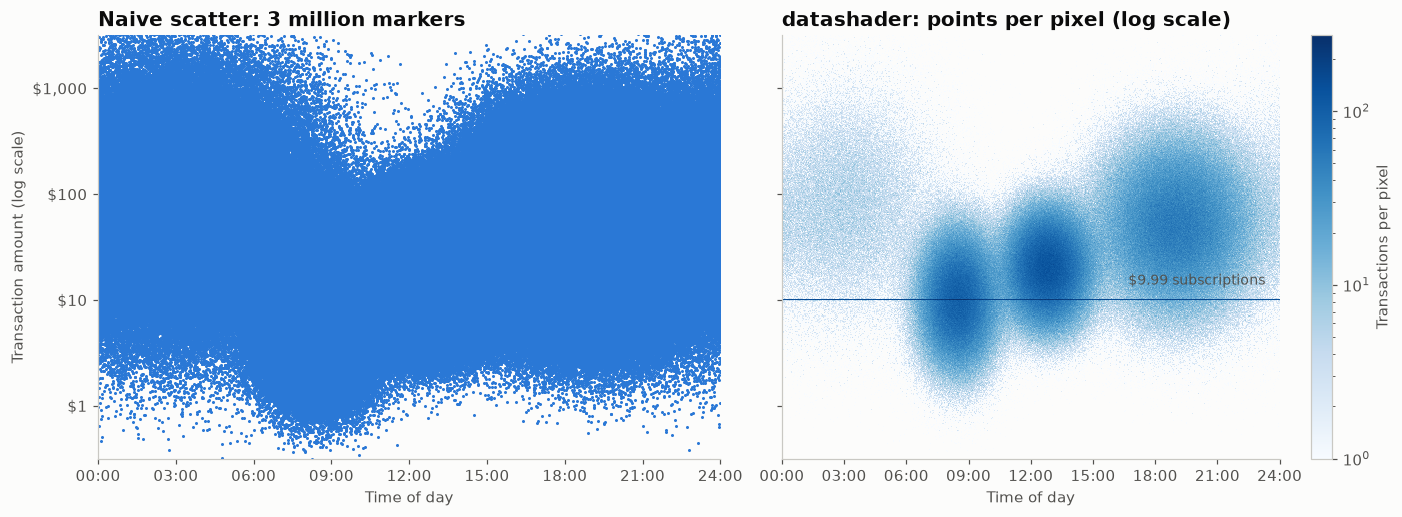

In [3]:
x_range, y_range = (0, 24), (-0.5, 3.5)
canvas = ds.Canvas(plot_width=800, plot_height=420, x_range=x_range, y_range=y_range)
counts = canvas.points(df, "hour", "log_amount", agg=ds.count()).values.astype(float)
counts[counts == 0] = np.nan

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
ax1.scatter(df["hour"].values, df["log_amount"].values, s=1, color=PALETTE[0], rasterized=True)
ax1.set_title(f"Naive scatter: {len(df) / 1e6:.0f} million markers")
im = ax2.imshow(counts, origin="lower", extent=[*x_range, *y_range], aspect="auto",
                cmap=SEQ_CMAP, norm=LogNorm(vmin=1, vmax=np.nanmax(counts)), interpolation="nearest")
ax2.set_title("datashader: points per pixel (log scale)")
fig.colorbar(im, ax=ax2, label="Transactions per pixel")
for ax in (ax1, ax2):
    ax.set_xlim(*x_range)
    ax.set_xticks(range(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])
    ax.set_xlabel("Time of day")
    ax.grid(False)
ax1.set_ylim(*y_range)
ax1.set_yticks(range(0, 4), ["$1", "$10", "$100", "$1,000"])
ax1.set_ylabel("Transaction amount (log scale)")
ax2.annotate("$9.99 subscriptions", (23.6, np.log10(9.99)), xytext=(-4, 10), textcoords="offset points",
             ha="right", fontsize=9, color="#52514e")
fig.tight_layout()
plt.show()

## How to read it

On the left, three million points merge into one blob and the structure is gone. On the right, each pixel is colored by its count on a log scale, so the lunchtime peak, the evening shopping band, the overnight lull and the thin horizontal line of identical $9.99 subscription charges all appear.

---
Standalone script: [`datashader_scatter.py`](datashader_scatter.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)